# 01 · BARQ X gate: design, robustness, and two-level noise

This is the first of four notebooks that follow one BARQ X gate from design
to a three-level device:

1. **01** (this one) designs the gate with BARQ, inspects its Frenet and
   control dictionaries and its robustness, and runs the two-level noise
   experiments.
2. **02** runs the same pulse on a three-level system (qutrit) and studies
   leakage to $|2\rangle$.
3. **03** applies DRAG at orders 1 and 2 and repeats the two- and three-level
   analysis.
4. **04** plays two X pulses back to back, which should give the identity.

Every quantity is obtained twice: once **calculated** from a first-order
formula and once **simulated** with QuTiP.

**Units.** The two-level simulation needs no physical gate time. Pulses live
on normalized time $t/T_g \in [0, 1]$, fields are reported as $T_g\Omega$
and $T_g\Delta$, and noise as $T_g\delta_z$ and $\varepsilon$. A physical
$T_g$ only matters once a second energy scale appears, the anharmonicity
$\alpha$ in notebook 02.

The design follows [Xgate_design_barq.ipynb](../Xgate_design_barq.ipynb).

In [1]:
import shutil

import jax
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd

from qurveros import barqtools, drag, losses, plottools
from qurveros.optspacecurve import BarqCurve
from qurveros.qubit_bench import noise_experiments, quantumtools, simulator
import qurveros.plot_configs

import xgate_setup as xs

matplotlib.rcParams['figure.dpi'] = 150

## Target gate and BARQ setup

The target is the Pauli X gate. BARQ fixes the gate through the adjoint
representation of the target in SU(2).

In [2]:
u_target = xs.U_TARGET
adj_target = quantumtools.calculate_adj_rep(u_target)
adj_target

array([[ 1.,  0., -0.],
       [ 0., -1., -0.],
       [ 0.,  0., -1.]])

As in the example, the point-gate-fixing (PGF) parameters near the
boundaries are tied to one `norm_value`, which sets the rise and fall of
the envelope.

In [3]:
@jax.jit
def xgate_pgf_mod(pgf_params, input_points):

    pgf_params_mod = pgf_params.copy()
    norm_set = pgf_params_mod['norm_value']

    pgf_params_mod['left_tangent_fix'] = norm_set
    pgf_params_mod['left_tangent_aux'] = norm_set
    pgf_params_mod['left_binormal_fix'] = norm_set
    pgf_params_mod['right_binormal_fix'] = norm_set
    pgf_params_mod['right_tangent_aux'] = norm_set
    pgf_params_mod['right_tangent_fix'] = norm_set
    pgf_params_mod['left_binormal_aux'] = pgf_params_mod['right_binormal_aux']

    return pgf_params_mod


barqcurve = BarqCurve(adj_target=adj_target,
                      n_free_points=10,
                      pgf_mod=xgate_pgf_mod)

barqcurve.prepare_optimization_loss(
    [losses.tantrix_zero_area_loss, 1],  # first-order drive-error robustness
    [losses.max_amp_loss, 1e-2])         # keep the peak amplitude small

init_pgf = barqtools.get_default_pgf_params_dict()
init_pgf['norm_value'] = 0.25
barqcurve.initialize_parameters(seed=4531469, init_pgf_params=init_pgf)

params_labels = jax.tree.map(lambda x: True, barqcurve.params)
params_labels['pgf_params']['norm_value'] = False
optimizer = optax.multi_transform(
    {True: optax.adam(learning_rate=0.001), False: optax.set_to_zero()},
    param_labels=params_labels)

## Optimize, or load the stored result

`RUN_OPTIMIZATION = True` runs the 50,000 Adam steps of the example, about
4 minutes on a 4-core CPU, and saves the new control points. With `False`
the notebook uses the control points stored with the package
(`results/control_points/xgate_step50000.csv`), which come from that same
run. Either way the points are written to `data/xgate_barq_points.csv`,
which notebooks 02–04 read.

The analysis below uses a `BezierCurve` rebuilt from those points. It is
the same curve as `barqcurve` and has the same Frenet, robustness, and
control methods.

In [4]:
RUN_OPTIMIZATION = False

if RUN_OPTIMIZATION:
    barqcurve.optimize(optimizer, max_iter=50000)
    xs.store_control_points(barqcurve)
else:
    xs.store_control_points()

xcurve = xs.load_xgate_curve()

## Frenet dictionary

The Frenet dictionary holds the curve $\vec r$, its moving frame
$(\vec T, \vec N, \vec B)$, curvature $\kappa$, torsion $\tau$, and
arclength. The curvature becomes the envelope $\Omega$ and the torsion the
phase rate.

In [5]:
frenet_dict = xcurve.get_frenet_dict()
print('keys:', sorted(frenet_dict.keys()))
print('samples:', len(frenet_dict['x_values']))
print(f"gate time (curve length) in curve units: {frenet_dict['length'][-1]:.4f}")
print(f"BARQ binormal angle: {frenet_dict['barq_angle']:.6f}")

keys: ['barq_angle', 'curvature', 'curve', 'deriv_array', 'frame', 'length', 'params', 'speed', 'torsion', 'x_values']
samples: 4096
gate time (curve length) in curve units: 1.4420
BARQ binormal angle: 3.412857


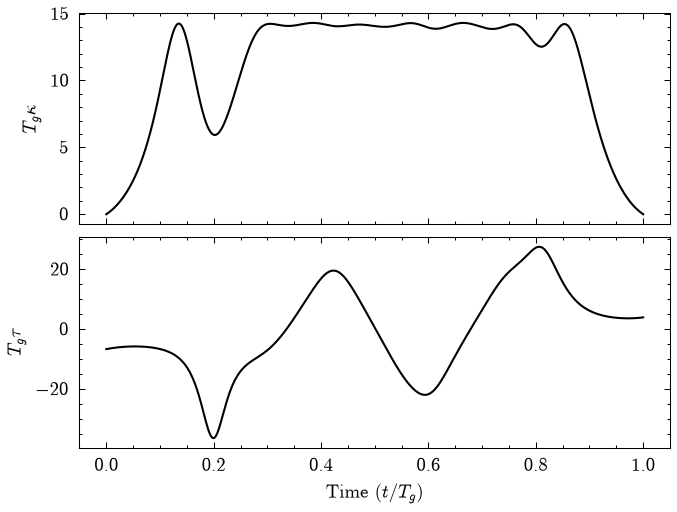

In [6]:
length = np.asarray(frenet_dict['length'])
s = length / length[-1]
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(4.5, 3.4),
                        layout='constrained')
axs[0].plot(s, length[-1] * np.asarray(frenet_dict['curvature']), color='k')
axs[0].set_ylabel(r'$T_g\kappa$')
axs[1].plot(s, length[-1] * np.asarray(frenet_dict['torsion']), color='k')
axs[1].set_ylabel(r'$T_g\tau$')
axs[1].set_xlabel(r'Time $(t/T_g)$')
plt.show()

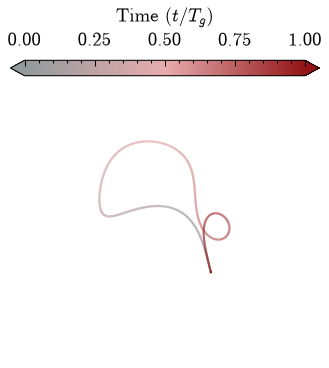

In [7]:
xcurve.plot_position()
plt.show()

## Robustness properties of the curve

These are the *calculated* robustness checks from the geometry:

- `closed_test`, $(\vec r(T_g) - \vec r(0))/T_g$: zero means first-order
  robustness to static dephasing.
- `tantrix_area_test`: zero means first-order robustness to a
  multiplicative drive error $\varepsilon$. BARQ minimized it, but it is not
  exactly zero.
- `curve_area_test`: the second-order dephasing term.
- `CFI`: the curve filtering index for $1/f^2$ dephasing noise.

In [8]:
xcurve.evaluate_robustness_properties()
robustness = xcurve.get_robustness_properties()
robustness_dict = robustness.get_robustness_dict()
robustness

|       closed_test       : 	 0.0000e+00
|     curve_area_test     : 	 3.5879e-03
|    tantrix_area_test    : 	 1.1872e-04
|           CFI           : 	 5.2288e-02

## Control dictionary

The TTC (total torsion compensation) mode turns the curve into
$\Omega(t)$, $\Phi(t)$, and a constant detuning $\Delta$. The control
dictionary is in the normalized units of the simulator.

In [9]:
xcurve.evaluate_control_dict('TTC', n_points=xs.N_POINTS)
control_dict = xcurve.get_control_dict()

print('keys:', sorted(control_dict.keys()))
print(f"T_g Omega_max = {control_dict['tg_envelope_max']:.4f}")
print(f"T_g Delta (constant TTC detuning) = {control_dict['delta'][0]:.4f}")
print(f"Gate fidelity from the curve's adjoint representation: "
      f"{xcurve.get_gate_fidelity(adj_target):.12f}")

keys: ['adj_curve', 'delta', 'omega', 'phi', 'singularity_idxs', 'tg_envelope_max', 'times']
T_g Omega_max = 14.3050
T_g Delta (constant TTC detuning) = 0.8508
Gate fidelity from the curve's adjoint representation: 1.000000000000


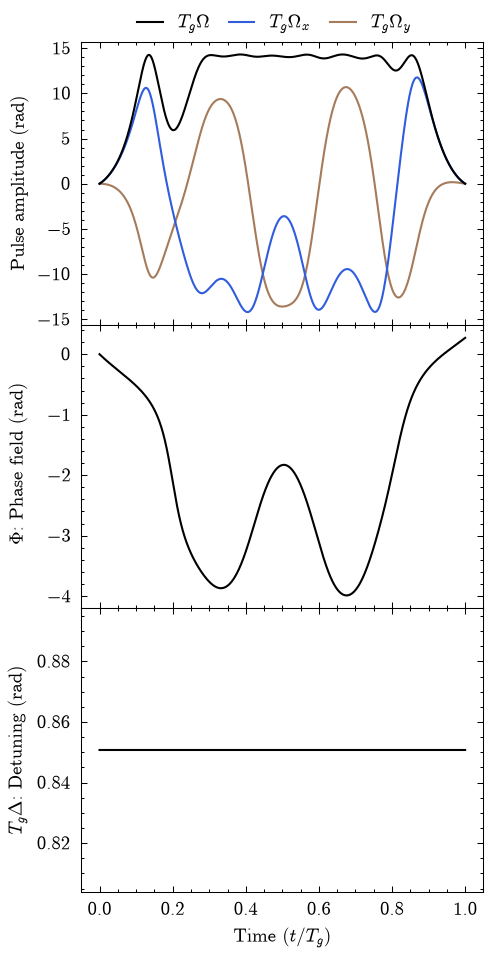

In [10]:
plottools.plot_fields(control_dict, 'full')
plt.show()

## Two-level simulation

QuTiP integrates
$H = \frac{\Omega}{2}(\cos\Phi\,\sigma_x + \sin\Phi\,\sigma_y) + \frac{\Delta}{2}\sigma_z$.

In [11]:
qubit_sim = simulator.simulate_control_dict(control_dict, u_target)
print(f"average gate fidelity: {qubit_sim['avg_gate_fidelity']:.14f}")
np.round(qubit_sim['u_final'], 6)

average gate fidelity: 0.99999999999985


array([[-0.+0.j,  0.+1.j],
       [-0.+1.j, -0.-0.j]])

## Calculated robustness from the pulse

`simulator.first_order_error_vectors` integrates the noise operators in the
toggling frame of the simulated evolution:

$$
\vec r_z=\int_0^1 \mathrm{adj}(U)^\dagger\hat z\,ds,\qquad
\vec r_\varepsilon=\int_0^1 T_g\Omega\,\mathrm{adj}(U)^\dagger(\cos\Phi,\sin\Phi,0)\,ds .
$$

To leading order the infidelities are $(T_g\delta_z)^2|\vec r_z|^2/6$ and
$\varepsilon^2|\vec r_\varepsilon|^2/6$. For a curve pulse $|\vec r_z|$ is
the curve closure and $|\vec r_\varepsilon|$ is the tantrix area, so this is
a check of the geometry against the simulated propagator. Unlike the curve
properties, it also works for pulses that DRAG has changed (notebook 03).

In [12]:
vectors = simulator.first_order_error_vectors(control_dict)

pd.DataFrame({
    'from the curve geometry': [np.linalg.norm(robustness_dict['closed_test']),
                                np.linalg.norm(robustness_dict['tantrix_area_test'])],
    'from the propagator': [vectors['r_z_norm'], vectors['r_epsilon_norm']],
}, index=['|r_z|  (closure)', '|r_eps| (tantrix area)'])

,from the curve geometry,from the propagator
|r_z| (closure),0.000000,6.709620e-12
|r_eps| (tantrix area),0.010896,1.089444e-02


## Two-level noise contour

Infidelity under simultaneous static dephasing $\frac{\delta_z}{2}\sigma_z$
and drive error $\Omega\to(1+\varepsilon)\Omega$.

Static additive dephasing and multiplicative driving field experiment



Multiplicative driving field error:	 0.00 %
	 \---- Static additive dephasing error:	25.00 %

	 \---- Static additive dephasing error:	75.00 %

Multiplicative driving field error:	 8.33 %
	 \---- Static additive dephasing error:	 8.33 %

	 \---- Static additive dephasing error:	58.33 %

...

Multiplicative driving field error:	83.33 %
	 \---- Static additive dephasing error:	41.67 %

	 \---- Static additive dephasing error:	91.67 %

Multiplicative driving field error:	91.67 %
	 \---- Static additive dephasing error:	33.33 %

	 \---- Static additive dephasing error:	83.33 %

Multiplicative driving field error:	100.00%


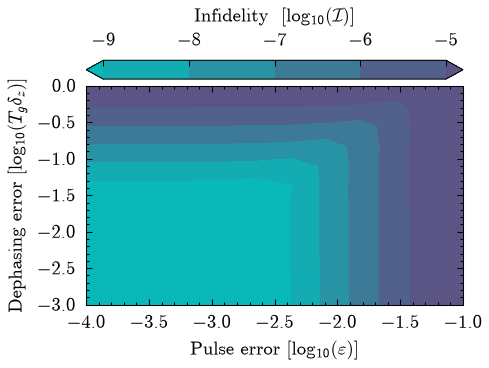

In [13]:
qubit_contour = noise_experiments.simult_source_experiment(control_dict, u_target)
xs.save_result('contour_qubit_bare', qubit_contour)

plottools.plot_noise_contour(qubit_contour)
plt.show()

## Calculated vs simulated noise response

Each noise source is now swept on its own. `xgate_setup.sensitivity_sweep`
reports the infidelity against X and the *sensitivity*: the infidelity of
the noisy gate against the noiseless one. The slope of the sensitivity on a
log–log plot is the order at which the noise enters. A slope of 2 means
first-order error. A slope of 4 means the first order cancels.

A plain Gaussian $\pi$ pulse is shown for reference. Dashed lines are the
first-order predictions from the error vectors.

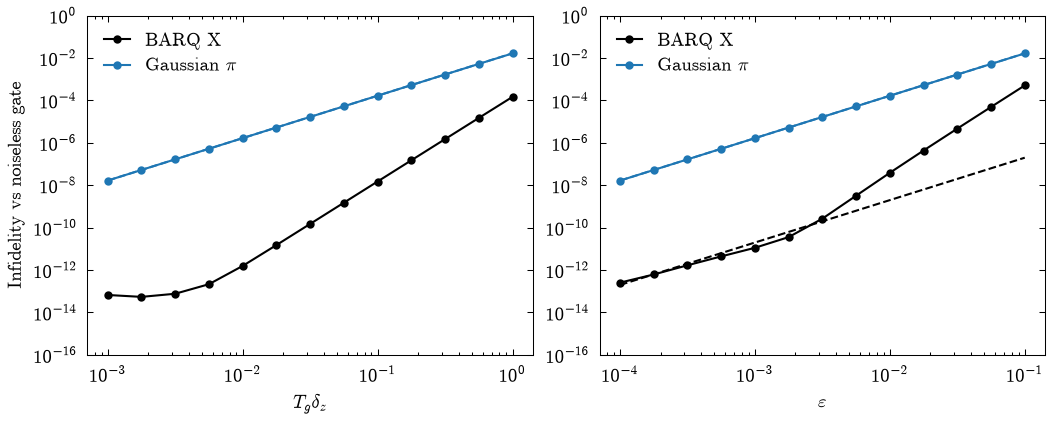

,"dephasing slope, 0.01-0.3","amplitude slope, eps <= 0.002","amplitude slope, eps >= 0.01",|r_z|,|r_eps|
BARQ X,3.987375,1.705802,4.116516,6.709620e-12,0.010894
Gaussian $\pi$,1.999888,1.999998,1.996762,3.149617e-01,3.141593


In [14]:
tg_delta_z = np.logspace(-3, 0, 13)
epsilons = np.logspace(-4, -1, 13)
gaussian = drag.gaussian_pi_control(n_points=xs.N_POINTS, sigma=0.15)

pulses = {'BARQ X': control_dict, 'Gaussian $\\pi$': gaussian}
sweeps = {}
for name, pulse in pulses.items():
    sweeps[name] = {
        'dephasing': xs.sensitivity_sweep(pulse, 'dephasing', tg_delta_z, u_target=u_target),
        'amplitude': xs.sensitivity_sweep(pulse, 'amplitude', epsilons, u_target=u_target),
        'vectors': simulator.first_order_error_vectors(pulse),
    }

fig, axs = plt.subplots(1, 2, figsize=(7, 2.8), layout='constrained')
for (name, sweep), color in zip(sweeps.items(), ['k', 'tab:blue']):
    axs[0].loglog(tg_delta_z, sweep['dephasing']['sensitivity'], 'o-', ms=3,
                  color=color, label=name)
    axs[0].loglog(tg_delta_z, (tg_delta_z * sweep['vectors']['r_z_norm'])**2 / 6,
                  '--', color=color)
    axs[1].loglog(epsilons, sweep['amplitude']['sensitivity'], 'o-', ms=3,
                  color=color, label=name)
    axs[1].loglog(epsilons, (epsilons * sweep['vectors']['r_epsilon_norm'])**2 / 6,
                  '--', color=color)
axs[0].set_xlabel(r'$T_g\delta_z$')
axs[1].set_xlabel(r'$\varepsilon$')
axs[0].set_ylabel('Infidelity vs noiseless gate')
for ax in axs:
    ax.set_ylim(1e-16, 1)
    ax.legend()
plt.show()

dephasing_window = (tg_delta_z >= 1e-2) & (tg_delta_z <= 0.3)
small_eps, large_eps = epsilons <= 2e-3, epsilons >= 1e-2
pd.DataFrame({
    name: {
        'dephasing slope, 0.01-0.3': xs.loglog_slope(
            tg_delta_z[dephasing_window], s['dephasing']['sensitivity'][dephasing_window]),
        'amplitude slope, eps <= 0.002': xs.loglog_slope(
            epsilons[small_eps], s['amplitude']['sensitivity'][small_eps]),
        'amplitude slope, eps >= 0.01': xs.loglog_slope(
            epsilons[large_eps], s['amplitude']['sensitivity'][large_eps]),
        '|r_z|': s['vectors']['r_z_norm'],
        '|r_eps|': s['vectors']['r_epsilon_norm'],
    } for name, s in sweeps.items()
}).T

**Reading the plots.**

- **Dephasing.** The BARQ curve is closed ($|\vec r_z|\sim10^{-11}$), so
  there is no first-order term: the response rises with slope 4, and
  below $T_g\delta_z\approx 5\times10^{-3}$ it sits on the
  $\sim10^{-13}$ accuracy floor of the ODE solver. The Gaussian has slope 2
  and lies on its dashed first-order prediction.
- **Drive error.** BARQ minimized the tantrix area without making it zero,
  so for $\varepsilon \lesssim 2\times10^{-3}$ the response follows the
  dashed first-order line $\varepsilon^2|\vec r_\varepsilon|^2/6$, about
  $10^{5}$ times below the Gaussian. For larger $\varepsilon$ the
  second-order term takes over and the slope becomes 4.
- The calculated error vectors and the simulated sweeps agree wherever the
  first order dominates.

## Save the pulse for the next notebooks

The control points are already in `data/`. The fields are saved too, for use
outside qurveros.

In [15]:
xcurve.save_control_dict(xs.DATA_DIR / 'xgate_barq_control.csv')
sorted(p.name for p in xs.DATA_DIR.iterdir())

['contour_qubit_bare.npz', 'xgate_barq_control.csv', 'xgate_barq_points.csv']